# Relatório da Modelagem

**Universidade Estadual de Montes Claros**  
**Especialização em Ciência de Dados**  
**Disciplina:** Trabalho de Conclusão de Curso  
**Aluno:** Luan Silva Gomes  

**Projeto:** Comparar o desempenho de diferentes modelos de aprendizado de máquina na predição da gravidade de acidentes de trânsito com vítimas ocorridos em Minas Gerais, utilizando dados provenientes da Base de Dados do Painel de Sinistro de Trânsito da Secretaria de Estado de Justiça e Segurança Pública de Minas Gerais, com o propósito de apoiar a priorização do atendimento de emergência às ocorrências.

Este notebook dá sequência à análise exploratória (`eda.ipynb` e `eda_10_years.ipynb`) e reúne a seleção de atributos, o treinamento dos modelos e a comparação entre os recortes temporais de 5 e de 10 anos.

# Importação de Dependências e Configurações Básicas

Os dados brutos estão armazenados no diretório `/data` deste projeto. Além das bibliotecas já utilizadas na análise exploratória, esta etapa utiliza o scikit-learn e o XGBoost.

In [1]:
import sys
import os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
if not DATA_DIR.exists() or not DATA_DIR.is_dir():
     raise FileNotFoundError(f"Diretório de dados '{DATA_DIR}' não encontrado")

In [2]:
import pandas as pd
from sklearn.model_selection import StratifiedKFold

from src.constants import (
    TEN_YEARS,
    TEST_YEAR,
    TRAIN_YEARS_5,
    TRAIN_YEARS_10,
    CANDIDATE_FEATURES,
    RANDOM_STATE
)

pd.set_option('display.max_colwidth', None)

# Preparação dos Dados

## 1. Base analítica

Nesta etapa, a base analítica é construída com as mesmas funções da análise exploratória, porém com os 10 anos de dados (2016 a 2025), para que os dois recortes sejam avaliados no mesmo conjunto de teste. Diferentemente da análise exploratória, a função `clean_missing_values` é chamada com `impute=False`, pois os valores faltantes são imputados dentro do pipeline de cada modelo, apenas com os dados de treino. Os registros sem coordenadas também são mantidos, já que latitude e longitude não são utilizadas como atributos.

In [3]:
from src.preprocessing import (
    get_df_per_data_group,
    build_analytical_base_table,
    apply_filters,
    clean_missing_values
)
from src.raining import load_inmet_precipitation_data

df_per_data_group = get_df_per_data_group(DATA_DIR, TEN_YEARS)
df_estacoes, df_precipitacao = load_inmet_precipitation_data(DATA_DIR / 'inmet')
df_final_abt = build_analytical_base_table(
    df_ocorrencias=df_per_data_group['ocorrencias'],
    df_vitimas=df_per_data_group['vitimas'],
    df_condicoes=df_per_data_group['condicoes'],
    df_via=df_per_data_group['via'],
    df_veiculos=df_per_data_group['veiculo'],
    df_estacoes=df_estacoes,
    df_precipitacao=df_precipitacao
)
filtered_df = apply_filters(df_final_abt, TEN_YEARS)
df_modelo = clean_missing_values(filtered_df, drop_missing_coordinates=False, impute=False)
print(f"Instâncias disponíveis para a modelagem: {len(df_modelo)}")

/Users/luangomes/Code/road-traffic-accident-severity-prediction-mg/src/preprocessing.py:20: DtypeWarning: Columns (0: oco_latitude_sirgas2000, 1: oco_longitude_sirgas2000) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=';', header=header, names=columns)
/Users/luangomes/Code/road-traffic-accident-severity-prediction-mg/src/preprocessing.py:20: DtypeWarning: Columns (0: vit_latitude_sirgas2000, 1: vit_longitude_sirgas2000) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(path, sep=';', header=header, names=columns)


1/4. Processando tabela base de ocorrências...
   -> Tabela base pronta com 2665653 ocorrências únicas.

2/4. Agrupando datasets secundários...
   -> Agrupamentos concluídos.

3/4. Realizando merges (LEFT JOINs)...
   -> Validação concluída: Nenhuma duplicata gerada no merge.

ABT gerada com sucesso! Dimensões finais: 2665653 linhas x 43 colunas.

Instâncias disponíveis para a modelagem: 650086


## 2. Divisão em treino e teste

In [4]:
from src.modeling import split_train_test_by_year, get_features_and_target

df_treino_5, df_teste = split_train_test_by_year(df_modelo, TRAIN_YEARS_5, TEST_YEAR)
df_treino_10, _ = split_train_test_by_year(df_modelo, TRAIN_YEARS_10, TEST_YEAR)

print("\nPercentual de acidentes graves por ano:")
display((df_modelo.groupby('oco_ano_fato')['acidente_grave'].mean() * 100).round(2).to_frame().T)

Treino (2021-2024): 245310 instâncias | 18.05% de acidentes graves
Teste (2025): 64643 instâncias | 16.41% de acidentes graves
Treino (2016-2024): 585443 instâncias | 18.02% de acidentes graves
Teste (2025): 64643 instâncias | 16.41% de acidentes graves

Percentual de acidentes graves por ano:


oco_ano_fato,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
acidente_grave,18.25,18.17,17.95,17.54,18.03,17.95,18.01,18.63,17.58,16.41


A divisão entre treino e teste é temporal. O ano de 2025 é o conjunto de teste nos dois recortes, e os modelos são treinados com os dados de 2021 a 2024, no recorte de 5 anos, ou de 2016 a 2024, no recorte de 10 anos, de modo que são avaliados em um ano que não participou do treinamento. A função `split_train_test_by_year` também garante que nenhuma ocorrência apareça ao mesmo tempo no treino e no teste.

Após a divisão, o conjunto de teste ficou com 64.643 acidentes, sendo 16,41% de ocorrências graves. Já os treinos dos recortes de 5 e 10 anos possuem 245.310 e 585.443 acidentes, respectivamente, ambos com cerca de 18% de graves.

# Seleção de Atributos

Nesta seção, a seleção de atributos é feita em quatro etapas:
1. Variância, para identificar atributos praticamente constantes.
2. Correlação de Pearson e F-score (ANOVA) de cada atributo com a variável alvo.
3. Identificação de atributos redundantes.
4. Análise das combinações, avaliando o desempenho com os k atributos de maior F-score.

Todas as etapas utilizam apenas o treino do recorte de 5 anos (2021 a 2024), que faz parte dos dois recortes, e a lista final de atributos é usada em ambos.

## 1. Atributos candidatos

Das 42 colunas da base filtrada, foram mantidos como candidatos os 33 atributos numéricos e binários construídos no pré-processamento (`CANDIDATE_FEATURES` em `/src/constants.py`). Ficaram de fora:
- `numero_ocorrencia_associado` e `acidente_grave`: Identificador da ocorrência e variável alvo.
- `oco_ano_fato`: O ano de teste (2025) não existe no treino.
- `oco_natureza_descricao`: Após o filtro de acidentes com vítimas, praticamente todos os registros têm o mesmo valor (99,96% no treino).
- `oco_nome_municipio`, `oco_nome_bairro` e `oco_tipo_logradouro_descricao`: Textos com muitas categorias.
- `oco_latitude_sirgas2000` e `oco_longitude_sirgas2000`: Estão em formato de texto e têm mais valores faltantes.

In [5]:
colunas_fora = [col for col in df_modelo.columns if col not in CANDIDATE_FEATURES]
print(f"Colunas da base filtrada: {df_modelo.shape[1]} | atributos candidatos: {len(CANDIDATE_FEATURES)}")
print(f"Colunas que não são candidatas: {colunas_fora}")

print("\nPercentual de cada natureza no treino (2021-2024):")
display((df_treino_5['oco_natureza_descricao'].value_counts(normalize=True) * 100).round(2))

print("\nQuantidade de categorias no treino (2021-2024):")
display(df_treino_5[['oco_nome_municipio', 'oco_nome_bairro', 'oco_tipo_logradouro_descricao']].nunique())

coordenadas = ['oco_latitude_sirgas2000', 'oco_longitude_sirgas2000']
print("\nTipo das colunas de coordenadas:")
print(df_modelo[coordenadas].dtypes)

print("\nPercentual de registros sem coordenadas por ano:")
display((df_modelo[coordenadas].isna().groupby(df_modelo['oco_ano_fato']).mean() * 100).round(2).T)

Colunas da base filtrada: 42 | atributos candidatos: 33
Colunas que não são candidatas: ['numero_ocorrencia_associado', 'oco_ano_fato', 'oco_tipo_logradouro_descricao', 'oco_natureza_descricao', 'oco_nome_bairro', 'oco_nome_municipio', 'oco_latitude_sirgas2000', 'oco_longitude_sirgas2000', 'acidente_grave']

Percentual de cada natureza no treino (2021-2024):


oco_natureza_descricao
ACIDENTE DE TRANSITO COM VITIMA    99.96
ACIDENTE DE TRANSITO SEM VITIMA     0.04
Name: proportion, dtype: float64


Quantidade de categorias no treino (2021-2024):


oco_nome_municipio                853
oco_nome_bairro                  7501
oco_tipo_logradouro_descricao     130
dtype: int64


Tipo das colunas de coordenadas:
oco_latitude_sirgas2000     str
oco_longitude_sirgas2000    str
dtype: object

Percentual de registros sem coordenadas por ano:


oco_ano_fato,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
oco_latitude_sirgas2000,13.02,12.5,13.0,12.08,11.25,8.15,6.73,4.16,0.85,1.0
oco_longitude_sirgas2000,13.02,12.5,13.0,12.08,11.25,8.15,6.73,4.16,0.85,1.0


In [6]:
X_treino_5, y_treino_5 = get_features_and_target(df_treino_5, CANDIDATE_FEATURES)
print(f"Atributos candidatos: {X_treino_5.shape[1]}")
print(f"Instâncias de treino usadas na seleção: {X_treino_5.shape[0]}")

Atributos candidatos: 33
Instâncias de treino usadas na seleção: 245310


## 2. Variância

In [7]:
from src.modeling import compute_features_variance

display(compute_features_variance(X_treino_5).round(4))

,atributo,tipo,variancia,coef_variacao,percentual_valor_1
0,qtd_defeitos_via,numérico,0.1611,3.7557,NaN
1,qtd_veiculos_envolvidos,numérico,0.3890,0.3745,NaN
2,qtd_vitimas,numérico,0.5332,0.5790,NaN
3,hora_fato,numérico,30.0632,0.3978,NaN
4,idade_media_vitimas,numérico,207.8208,0.4145,NaN
5,idade_maxima_vitima,numérico,236.0801,0.4230,NaN
6,has_via_sulcos_horizontais,binário,0.0055,NaN,0.5499
7,has_material_na_pista,binário,0.0055,NaN,0.5544
8,has_via_rachadura,binário,0.0113,NaN,1.1439
9,has_registro_veiculo,binário,0.0155,NaN,98.4301


Variância muito baixa indica que um atributo possui quase sempre o mesmo valor e pouco contribui para identificar se um acidente é grave ou não. Como a variância depende da unidade de medida, a tabela também mostra o coeficiente de variação (desvio padrão dividido pela média) dos atributos numéricos e, para os binários, o percentual de valores 1.

Nenhum atributo numérico apresenta variância próxima de zero. Os coeficientes de variação estão entre 0,37 (`qtd_veiculos_envolvidos`) e 3,76 (`qtd_defeitos_via`). Entre os binários, os menos frequentes são `has_via_sulcos_horizontais` e `has_material_na_pista` (0,55% dos acidentes) e `has_via_rachadura` (1,14%). Contudo, nesses casos, a variância baixa reflete apenas a raridade do evento. O atributo `is_noite_sem_iluminacao`, por exemplo, ocorre em apenas 4,98% dos acidentes e é o de maior correlação com a gravidade. Por isso, o critério de variância foi aplicado somente aos atributos numéricos, e nenhum atributo foi descartado nesta etapa.

## 3. Correlação de Pearson com a variável alvo

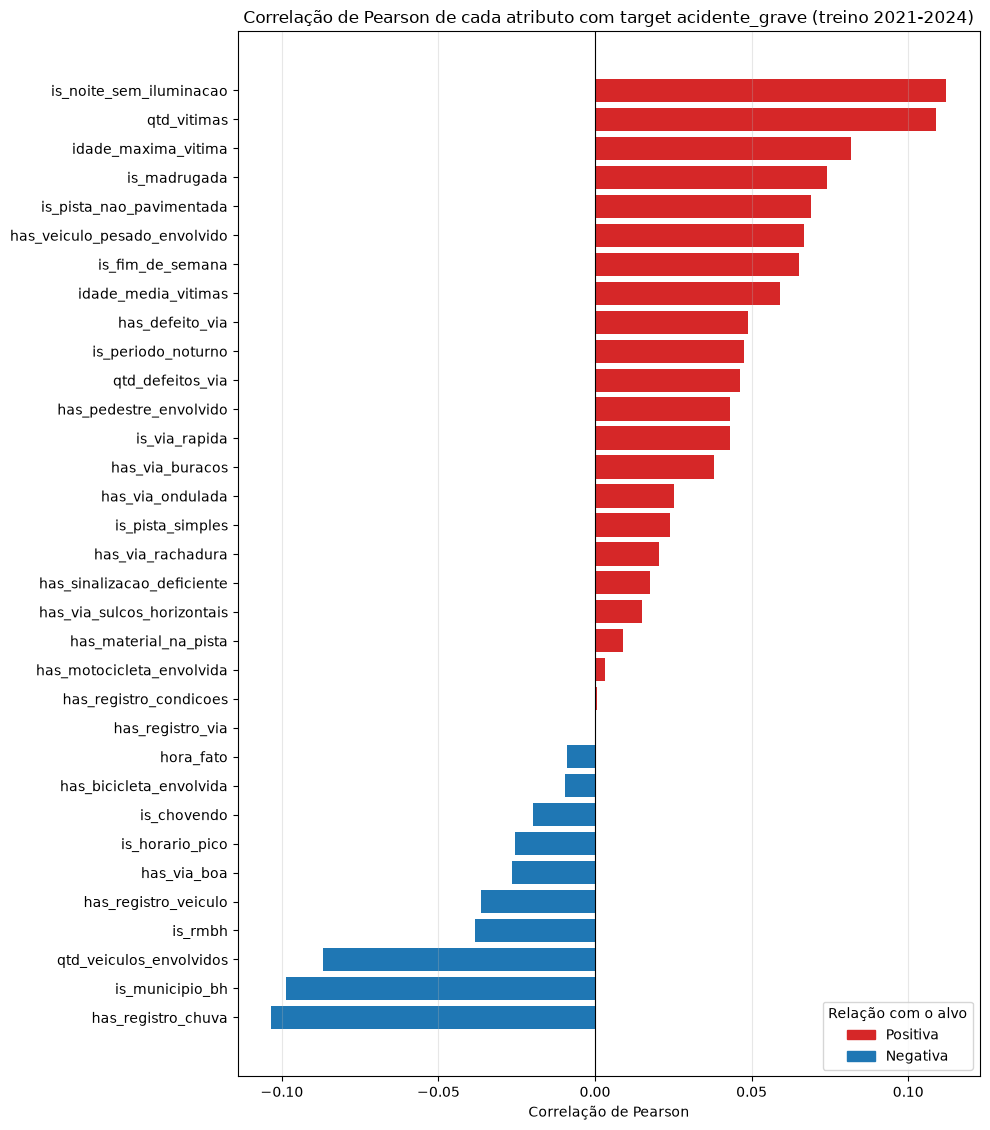

In [8]:
from src.modeling import compute_feature_relevance
from src.visualization import plot_scores_atributos

relevancia = compute_feature_relevance(X_treino_5, y_treino_5)
plot_scores_atributos(relevancia['pearson'], 'Correlação de Pearson de cada atributo com target acidente_grave (treino 2021-2024)', 'Correlação de Pearson')

A correlação de Pearson mede a força e a direção da relação linear entre cada atributo e a variável alvo. As maiores correlações positivas são as de:
- `is_noite_sem_iluminacao`
- `qtd_vitimas`
- `idade_maxima_vitima`

Já as maiores negativas são as de:
- `has_registro_chuva`
- `is_municipio_bh`
- `qtd_veiculos_envolvidos`

Em módulo, os valores são baixos, o que também já havia sido observado no heatmap da análise exploratória.

## 4. F-score (ANOVA)

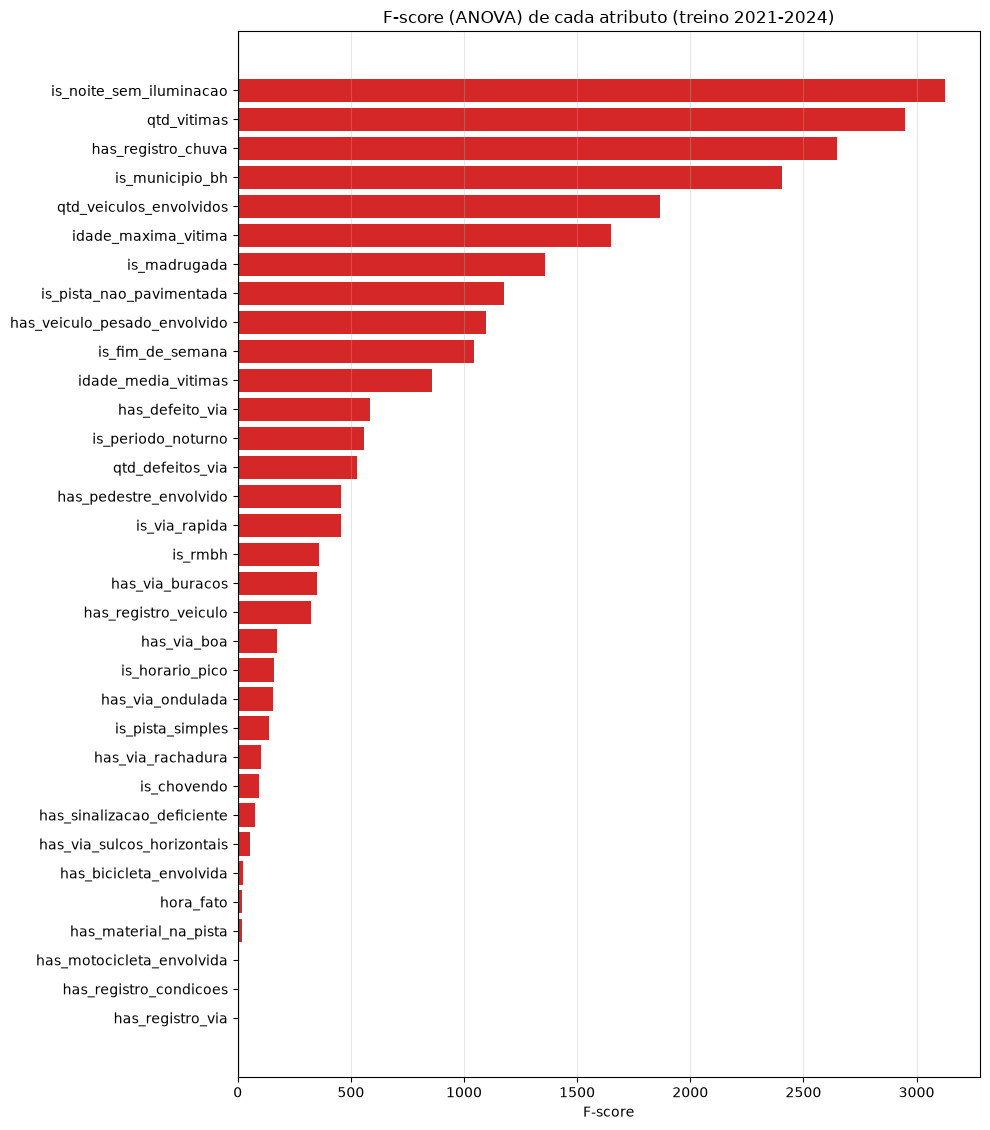

,pearson,abs_pearson,f_score,p_valor
atributo,,,,
is_noite_sem_iluminacao,0.1121,0.1121,3124.1895,0.0000
qtd_vitimas,0.1090,0.1090,2947.6476,0.0000
has_registro_chuva,-0.1033,0.1033,2646.6219,0.0000
is_municipio_bh,-0.0986,0.0986,2405.8769,0.0000
qtd_veiculos_envolvidos,-0.0869,0.0869,1868.3365,0.0000
idade_maxima_vitima,0.0817,0.0817,1649.4825,0.0000
is_madrugada,0.0742,0.0742,1357.4259,0.0000
is_pista_nao_pavimentada,0.0691,0.0691,1176.6197,0.0000
has_veiculo_pesado_envolvido,0.0667,0.0667,1097.3171,0.0000


In [9]:
plot_scores_atributos(relevancia['f_score'], 'F-score (ANOVA) de cada atributo (treino 2021-2024)', 'F-score')
display(relevancia.round(4))

In [10]:
ranking_f_score = relevancia.index.tolist()
ranking_pearson = relevancia.sort_values('abs_pearson', ascending=False).index.tolist()
print(f"O ranking pelo F-score é igual ao ranking pelo módulo da correlação de Pearson? -> {ranking_f_score == ranking_pearson}")

print("\nPercentual de acidentes graves por hora do fato (treino 2021-2024):")
display((df_treino_5.groupby('hora_fato')['acidente_grave'].mean() * 100).round(1).to_frame().T)

O ranking pelo F-score é igual ao ranking pelo módulo da correlação de Pearson? -> True

Percentual de acidentes graves por hora do fato (treino 2021-2024):


hora_fato,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
acidente_grave,30.8,25.8,28.3,28.7,31.2,27.0,20.7,14.8,13.5,15.1,...,16.5,16.8,18.0,17.5,18.4,18.8,19.7,20.3,20.4,22.7


O F-score, calculado pela função `f_classif`, mede o quanto a média do atributo nos acidentes graves se afasta da média nos não graves, em relação à dispersão dentro de cada grupo. O ranking obtido por ele é idêntico ao ranking pelo módulo da correlação de Pearson.

Contudo, as duas medidas captam apenas relações lineares. Por exemplo: a proporção de graves é de 30,8% à meia-noite, cai para 13,5% às 8h e volta a subir até 22,7% às 23h. Assim, `hora_fato` fica com correlação de apenas -0,009. Consequentemente, um F-score baixo não é motivo suficiente para descartar um atributo.

## 5. Atributos redundantes

In [11]:
from src.modeling import find_high_correlation_pairs

display(find_high_correlation_pairs(X_treino_5, threshold=0.85))

,atributo_1,atributo_2,correlacao
0,has_registro_condicoes,has_registro_via,0.985893
1,idade_media_vitimas,idade_maxima_vitima,0.953982
2,qtd_defeitos_via,has_defeito_via,0.877077
3,has_via_boa,has_registro_via,0.858193


In [12]:
print(f"Correlação entre has_via_boa e has_registro_condicoes: {X_treino_5['has_via_boa'].corr(X_treino_5['has_registro_condicoes']):.3f}")

Correlação entre has_via_boa e has_registro_condicoes: 0.849


Como manter os dois atributos de um par redundante não acrescenta informação e dificulta a interpretação dos coeficientes dos modelos lineares, a função `find_high_correlation_pairs` foi utilizada para listar os pares com correlação, em módulo, igual ou superior a 0,85 no treino. Foram encontrados quatro pares. Em cada um deles, descartou-se o atributo de menor F-score:
- `has_registro_condicoes` e `has_registro_via` (correlação = 0,986): descartou-se `has_registro_via`.
- `idade_media_vitimas` e `idade_maxima_vitima` (correlação = 0,954): descartou-se `idade_media_vitimas`.
- `qtd_defeitos_via` e `has_defeito_via` (correlação = 0,877): descartou-se `qtd_defeitos_via`.
- `has_via_boa` e `has_registro_via` (correlação = 0,858): descartou-se `has_registro_via`.

O par `has_via_boa` e `has_registro_condicoes` (correlação = 0,849) foi mantido. A correlação alta ocorre porque `has_via_boa` só vale 1 quando há registro da via, que quase sempre coincide com o registro de condições. Juntos, os dois distinguem ocorrência sem registro, via que não está em boas condições e via em boas condições.

In [13]:
atributos_redundantes = ['has_registro_via', 'idade_media_vitimas', 'qtd_defeitos_via']
FEATURES = [col for col in CANDIDATE_FEATURES if col not in atributos_redundantes]

X_treino_5, y_treino_5 = get_features_and_target(df_treino_5, FEATURES)
X_treino_10, y_treino_10 = get_features_and_target(df_treino_10, FEATURES)
X_teste, y_teste = get_features_and_target(df_teste, FEATURES)
print(f"Atributos mantidos após análise de redundância: {len(FEATURES)}")

Atributos mantidos após análise de redundância: 30


## 6. Análise das combinações: desempenho por número de atributos

Por fim, os atributos são ordenados pelo F-score e, para cada k entre 1 e 30, um modelo é treinado apenas com os k primeiros, medindo-se a PR-AUC (área sob a curva de precisão e recall) por validação cruzada. O `SelectKBest` fica dentro do pipeline, de modo que o ranking é recalculado apenas com os dados de treino de cada parte. A análise foi feita com a Regressão Logística e o HistGradientBoosting, representando, respectivamente, os modelos lineares e os baseados em árvores. A coluna `atributo_adicionado` indica o atributo que entra em cada k.

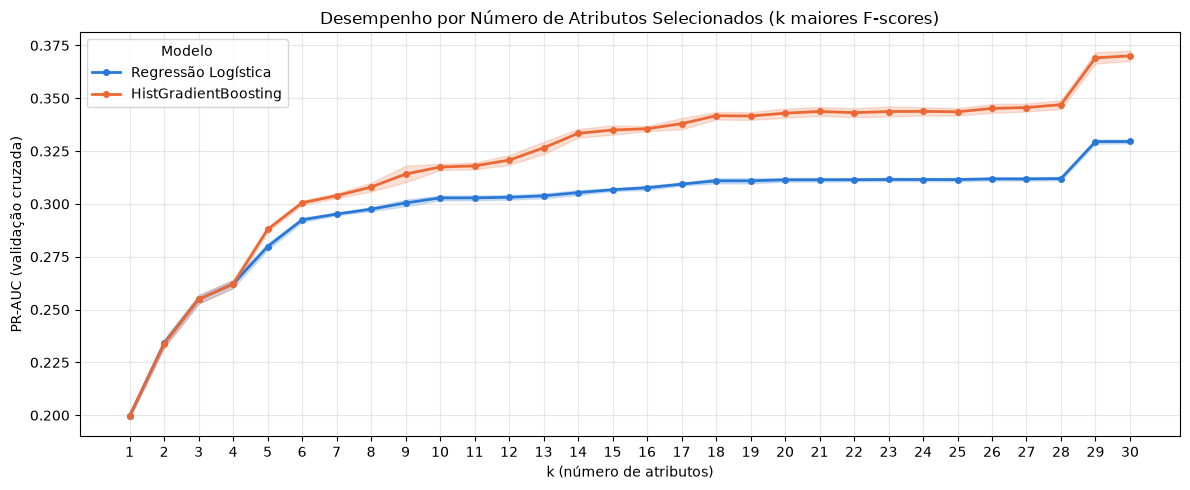

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from src.modeling import evaluate_k_best_features
from src.visualization import plot_desempenho_por_k

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

desempenho_k_lr = evaluate_k_best_features(
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    X_treino_5, y_treino_5, cv, scale=True, n_jobs=-1
)
desempenho_k_hgb = evaluate_k_best_features(
    HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
    X_treino_5, y_treino_5, cv, n_jobs=-1
)
plot_desempenho_por_k({'Regressão Logística': desempenho_k_lr, 'HistGradientBoosting': desempenho_k_hgb})

In [15]:
desempenho_k = desempenho_k_lr.merge(desempenho_k_hgb, on=['k', 'atributo_adicionado'], suffixes=('_lr', '_hgb'))
display(desempenho_k.round(4))

,k,atributo_adicionado,pr_auc_media_lr,pr_auc_desvio_lr,pr_auc_media_hgb,pr_auc_desvio_hgb
0,1,is_noite_sem_iluminacao,0.1997,0.0010,0.1997,0.0010
1,2,qtd_vitimas,0.2340,0.0019,0.2338,0.0018
2,3,has_registro_chuva,0.2549,0.0020,0.2549,0.0021
3,4,is_municipio_bh,0.2621,0.0018,0.2621,0.0020
4,5,qtd_veiculos_envolvidos,0.2798,0.0015,0.2879,0.0011
5,6,idade_maxima_vitima,0.2925,0.0011,0.3005,0.0010
6,7,is_madrugada,0.2952,0.0006,0.3039,0.0011
7,8,is_pista_nao_pavimentada,0.2975,0.0009,0.3080,0.0021
8,9,has_veiculo_pesado_envolvido,0.3005,0.0016,0.3141,0.0039
9,10,is_fim_de_semana,0.3028,0.0011,0.3175,0.0015


In [16]:
from sklearn.model_selection import cross_val_score
from src.modeling import build_model_pipeline

# Atributos que entram antes da motocicleta no ranking e o atributo que entra logo antes dela
ranking = desempenho_k_lr['atributo_adicionado'].tolist()
posicao_moto = ranking.index('has_motocicleta_envolvida')
atributos_anteriores = ranking[:posicao_moto - 1]
atributo_vizinho = ranking[posicao_moto - 1]

modelos_k = {
    'regressao_logistica': (LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE), True),
    'hist_gradient_boosting': (HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE), False),
}

linhas = []
for atributo_extra in [None, atributo_vizinho, 'has_motocicleta_envolvida']:
    colunas = atributos_anteriores + ([atributo_extra] if atributo_extra else [])
    linha = {'atributos': f'{len(atributos_anteriores)} primeiros' + (f' + {atributo_extra}' if atributo_extra else '')}
    for nome, (modelo, scale) in modelos_k.items():
        scores = cross_val_score(build_model_pipeline(modelo, scale), X_treino_5[colunas], y_treino_5, cv=cv, scoring='average_precision', n_jobs=-1)
        linha[f'pr_auc_{nome}'] = scores.mean()
    linhas.append(linha)

print(f"PR-AUC (validação cruzada) com os {len(atributos_anteriores)} primeiros atributos do ranking e com cada um dos dois atributos seguintes:")
display(pd.DataFrame(linhas).set_index('atributos').round(4))

PR-AUC (validação cruzada) com os 27 primeiros atributos do ranking e com cada um dos dois atributos seguintes:


,pr_auc_regressao_logistica,pr_auc_hist_gradient_boosting
atributos,,
27 primeiros,0.3120,0.3467
27 primeiros + has_material_na_pista,0.3120,0.3470
27 primeiros + has_motocicleta_envolvida,0.3295,0.3693


Nos dois modelos, a PR-AUC cresce rapidamente com os primeiros atributos. Entre k = 18 e k = 28, ambos praticamente se estabiliza.

Depois dos primeiros atributos, o maior salto ocorre com a entrada de `has_motocicleta_envolvida`, um dos atributos de menor F-score. Adicionado aos 27 primeiros, ele eleva a PR-AUC de 0,3120 para 0,3295 na Regressão Logística e de 0,3467 para 0,3693 no HistGradientBoosting. Equanto `has_material_na_pista` (k = 28) não altera o desempenho (0,3120 e 0,3470).

Como nenhum dos dois modelos perde desempenho com os 30 atributos, nenhum atributo foi descartado nesta etapa. Dessa forma, o conjunto final é formado pelos 30 atributos que restaram após a remoção dos redundantes, e o `SelectKBest` do pipeline permanece configurado com todos eles.

# Modelagem (treino de 5 anos: 2021 a 2024)

## 1. Estratégia de validação e métricas

Na primeira etapa, o baseline e os modelos lineares são comparados para escolher o melhor deles. Na segunda, os modelos não lineares são comparados com esse modelo, e os três melhores seguem como finalistas. O conjunto de teste (2025) só é utilizado depois dessas escolhas.
Observações:
- Como a base é desbalanceada (cerca de 18% dos acidentes do treino são graves), os modelos que permitem pesos por classe dão peso maior à classe grave (`class_weight='balanced'` ou, no XGBoost, `scale_pos_weight`), e os demais são treinados sem pesos. 
- Como métrica principal será utilizada a PR-AUC (`average_precision`) e a ROC-AUC é usada como complementar.

## 2. Etapa 1: baseline e modelos lineares

[Dummy (baseline)] PR-AUC = 0.1805 ± 0.0000 (0.0 min)
[Regressão Logística] PR-AUC = 0.3296 ± 0.0008 (0.1 min)
[LDA] PR-AUC = 0.3291 ± 0.0012 (0.0 min)
[Ridge] PR-AUC = 0.3269 ± 0.0006 (0.0 min)
[LinearSVC] PR-AUC = 0.3291 ± 0.0008 (0.1 min)
[SGD] PR-AUC = 0.3293 ± 0.0011 (0.2 min)
[Perceptron] PR-AUC = 0.2410 ± 0.0175 (0.1 min)
[Nearest Centroid] PR-AUC = 0.2985 ± 0.0011 (0.0 min)
[Naive Bayes (Bernoulli)] PR-AUC = 0.2944 ± 0.0007 (0.0 min)
[Naive Bayes (Multinomial)] PR-AUC = 0.2746 ± 0.0018 (0.0 min)
[Naive Bayes (Complement)] PR-AUC = 0.2746 ± 0.0018 (0.0 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
Regressão Logística,0.3296,0.0008,0.6914,0.0027,{'model__C': 0.001},5,0.1
SGD,0.3293,0.0011,0.6911,0.0027,"{'model__alpha': 0.01, 'model__loss': 'log_loss'}",8,0.2
LinearSVC,0.3291,0.0008,0.6910,0.0026,{'model__C': 0.001},4,0.1
LDA,0.3291,0.0012,0.6902,0.0026,{},1,0.0
Ridge,0.3269,0.0006,0.6894,0.0024,{'model__alpha': 1000},5,0.0
Nearest Centroid,0.2985,0.0011,0.6657,0.0016,{'model__shrink_threshold': 1.0},4,0.0
Naive Bayes (Bernoulli),0.2944,0.0007,0.6713,0.0025,{'model__alpha': 0.01},3,0.0
Naive Bayes (Multinomial),0.2746,0.0018,0.6345,0.0019,{'model__alpha': 0.01},3,0.0
Naive Bayes (Complement),0.2746,0.0018,0.6345,0.0019,{'model__alpha': 0.01},3,0.0


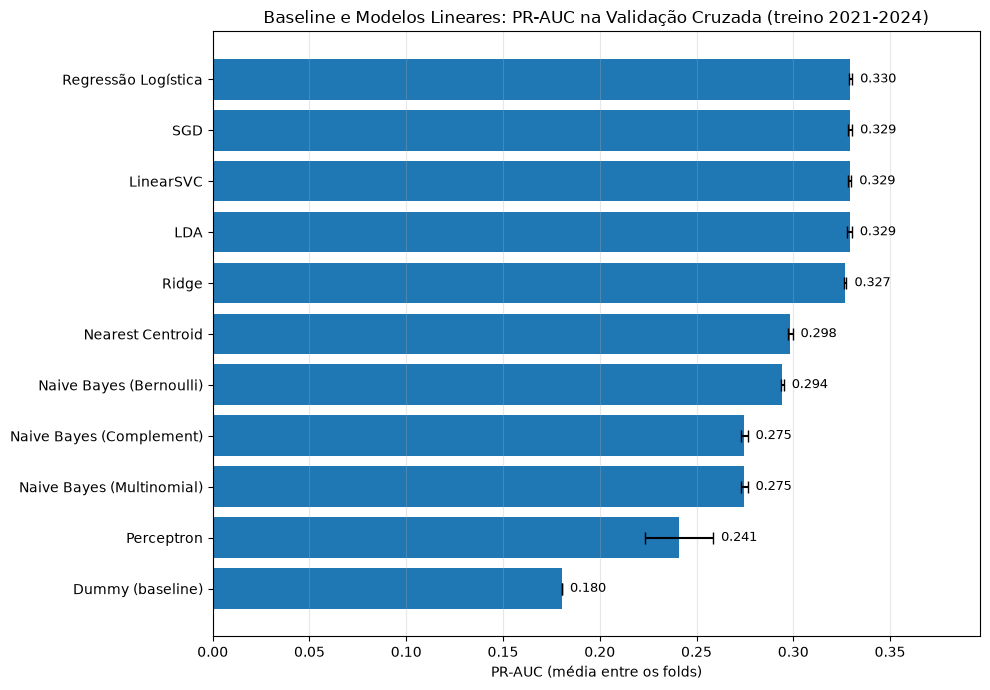

In [17]:
from src.modeling import get_linear_models, tune_models
from src.visualization import plot_comparacao_modelos

resultados_lineares_5, modelos_lineares_5 = tune_models(get_linear_models(), X_treino_5, y_treino_5, cv)
display(resultados_lineares_5.round(4))
plot_comparacao_modelos(resultados_lineares_5, titulo='Baseline e Modelos Lineares: PR-AUC na Validação Cruzada (treino 2021-2024)')

In [18]:
melhor_linear = resultados_lineares_5.drop(index='Dummy (baseline)').index[0]
print(f"Melhor modelo linear: {melhor_linear}")

Melhor modelo linear: Regressão Logística


Além do baseline, foram avaliados os classificadores lineares do scikit-learn viáveis nesta base. Por fim, todos os modelos lineares superam o baseline, cuja PR-AUC (0,1805) é igual à proporção de graves no treino. A Regressão Logística, o SGD, o LinearSVC e a LDA ficaram praticamente empatados, com diferença máxima de 0,0005 entre eles, seguidos pelo Ridge. Os demais ficaram bem abaixo, e o Perceptron teve o pior resultado e a maior variação entre as partições. Dessa forma, a Regressão Logística (C = 0,001) foi escolhida como o melhor modelo linear, por ter a maior PR-AUC média (0,3296).

## 3. Etapa 2: modelos não lineares

[HistGradientBoosting] PR-AUC = 0.3710 ± 0.0017 (0.8 min)
[Random Forest] PR-AUC = 0.3620 ± 0.0038 (3.3 min)
[XGBoost] PR-AUC = 0.3708 ± 0.0023 (0.6 min)
[Gradient Boosting] PR-AUC = 0.3704 ± 0.0016 (3.8 min)
[AdaBoost] PR-AUC = 0.3433 ± 0.0057 (2.5 min)
[Extra Trees] PR-AUC = 0.3600 ± 0.0042 (3.9 min)
[Bagging] PR-AUC = 0.3548 ± 0.0029 (4.3 min)
[Árvore de Decisão] PR-AUC = 0.3398 ± 0.0025 (0.1 min)
[Extra Tree] PR-AUC = 0.3102 ± 0.0037 (0.1 min)
[KNN] PR-AUC = 0.3425 ± 0.0045 (2.8 min)
[Radius Neighbors] PR-AUC = 0.3135 ± 0.0020 (1.5 min)
[MLP] PR-AUC = 0.3620 ± 0.0024 (3.5 min)
[QDA] PR-AUC = 0.2923 ± 0.0012 (0.1 min)
[Naive Bayes (Gaussiano)] PR-AUC = 0.2740 ± 0.0015 (0.1 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
HistGradientBoosting,0.3710,0.0017,0.7166,0.0034,"{'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_iter': 200, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}",10,0.8
XGBoost,0.3708,0.0023,0.7166,0.0037,"{'model__subsample': 0.8, 'model__n_estimators': 800, 'model__min_child_weight': 10, 'model__max_depth': 4, 'model__learning_rate': 0.03, 'model__colsample_bytree': 1.0}",10,0.6
Gradient Boosting,0.3704,0.0016,0.7157,0.0035,"{'model__subsample': 1.0, 'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__learning_rate': 0.1}",10,3.8
Random Forest,0.3620,0.0038,0.7113,0.0038,"{'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': None}",10,3.3
MLP,0.3620,0.0024,0.7121,0.0031,"{'model__alpha': 0.01, 'model__hidden_layer_sizes': (100,)}",9,3.5
Extra Trees,0.3600,0.0042,0.7081,0.0035,"{'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': 15}",10,3.9
Bagging,0.3548,0.0029,0.7094,0.0036,"{'model__max_samples': 0.5, 'model__estimator__min_samples_leaf': 50, 'model__estimator__max_depth': 15}",10,4.3
AdaBoost,0.3433,0.0057,0.7044,0.0041,"{'model__n_estimators': 100, 'model__learning_rate': 1.0, 'model__estimator__max_depth': 3}",10,2.5
KNN,0.3425,0.0045,0.6985,0.0033,"{'model__n_neighbors': 200, 'model__weights': 'uniform'}",10,2.8


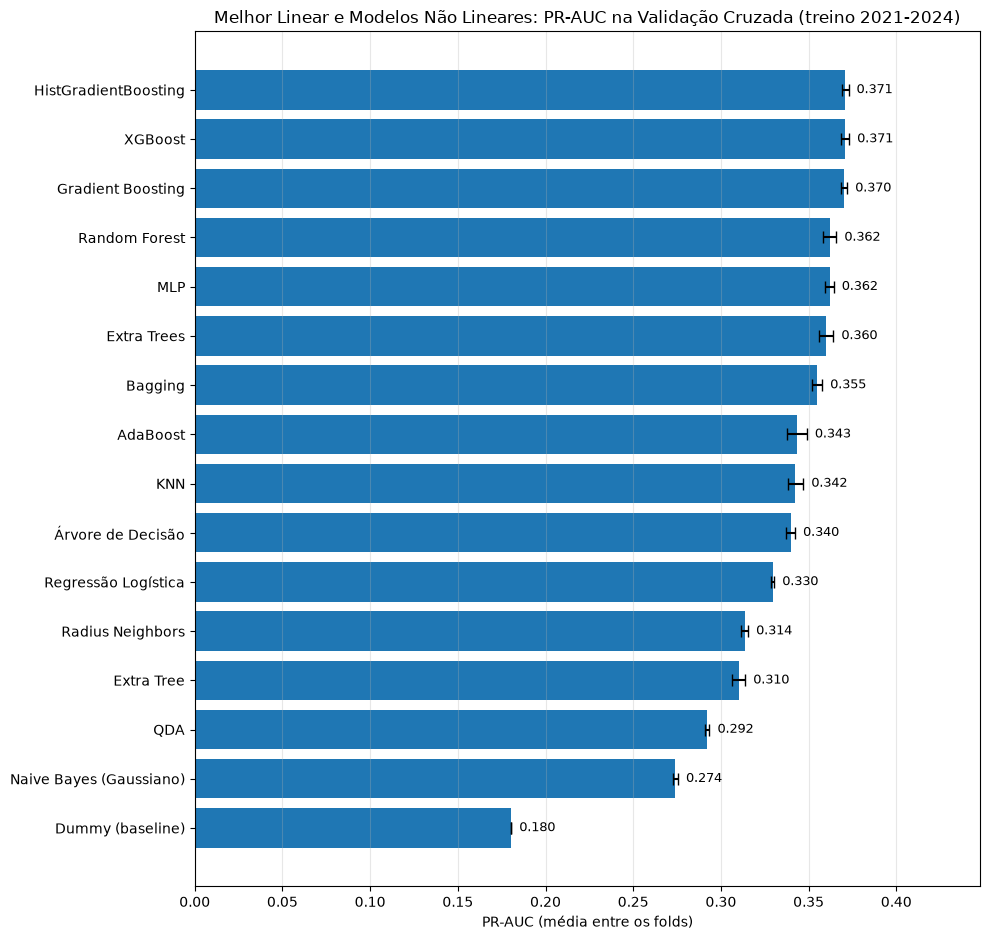

In [19]:
from src.modeling import get_nonlinear_models

scale_pos_weight_5 = (y_treino_5 == 0).sum() / (y_treino_5 == 1).sum()
resultados_nao_lineares_5, modelos_nao_lineares_5 = tune_models(get_nonlinear_models(scale_pos_weight_5), X_treino_5, y_treino_5, cv, n_iter=10)

resultados_5 = pd.concat([
    resultados_lineares_5.loc[['Dummy (baseline)', melhor_linear]],
    resultados_nao_lineares_5
]).sort_values('pr_auc_media', ascending=False)
display(resultados_5.round(4))
plot_comparacao_modelos(resultados_5, titulo='Melhor Linear e Modelos Não Lineares: PR-AUC na Validação Cruzada (treino 2021-2024)')

In [20]:
finalistas_nao_lineares = resultados_nao_lineares_5.index[:3].tolist()
print(f"Finalistas não lineares: {finalistas_nao_lineares}")

Finalistas não lineares: ['HistGradientBoosting', 'XGBoost', 'Gradient Boosting']


Na segunda etapa, foram avaliados 14 classificadores não lineares, comparados na tabela acima com o baseline e a Regressão Logística. Alguns classificadores do scikit-learn ficaram de fora por serem inviáveis com esse volume de dados (`SVC`, `NuSVC` e `GaussianProcessClassifier`) ou por não serem adequados a este problema (`LabelPropagation`, `LabelSpreading` e `CategoricalNB`). No Radius Neighbors, o maior raio testado foi 3, pois a memória necessária para a previsão aumenta rapidamente com o raio.

Os três modelos de gradient boosting ficaram à frente e praticamente empatados: HistGradientBoosting (0,3710), XGBoost (0,3708) e Gradient Boosting (0,3704). Em seguida aparecem a Random Forest, o MLP, a Extra Trees, o Bagging, o AdaBoost, o KNN e a Árvore de Decisão, todos acima da Regressão Logística (0,3296). Contudo, o Radius Neighbors, a Extra Tree, a QDA e o Naive Bayes gaussiano ficaram abaixo dela, ou seja, nem todo modelo não linear superou o modelo linear.

Em relação à Regressão Logística, o HistGradientBoosting teve um ganho de 0.0414 na PR-AUC, aproximadamente 13%. Assim, conforme a estratégia definida, os três modelos de gradient boosting seguem como finalistas para o teste, e o HistGradientBoosting, por ter a maior PR-AUC média, é usado como referência nas comparações.

## 4. Escolha do limiar de decisão

Os acidentes com score igual ou superior a um limiar são classificados como graves. Em vez do limiar padrão de 0,5, o limiar de cada modelo (baseline, Regressão Logística e finalistas) foi escolhido como o valor que maximiza o F1 da classe grave nas previsões fora da partição (`cross_val_predict`) do treino, sem utilizar o teste. Nos modelos treinados com pesos, o limiar escolhido fica próximo de 0,5. Já no Gradient Boosting, treinado sem pesos, ele fica em 0,20.

In [21]:
from src.modeling import find_best_threshold

modelos_finais_5 = {
    'Dummy (baseline)': modelos_lineares_5['Dummy (baseline)'],
    melhor_linear: modelos_lineares_5[melhor_linear],
    **{nome: modelos_nao_lineares_5[nome] for nome in finalistas_nao_lineares}
}

limiares_5 = {}
for nome, modelo in modelos_finais_5.items():
    limiar, f1_treino = find_best_threshold(modelo, X_treino_5, y_treino_5, cv)
    limiares_5[nome] = limiar
    print(f"[{nome}] limiar = {limiar:.4f} | F1 fora do fold = {f1_treino:.4f}")

[Dummy (baseline)] limiar = 0.1805 | F1 fora do fold = 0.3057
[Regressão Logística] limiar = 0.5179 | F1 fora do fold = 0.3956
[HistGradientBoosting] limiar = 0.5437 | F1 fora do fold = 0.4154
[XGBoost] limiar = 0.5512 | F1 fora do fold = 0.4146
[Gradient Boosting] limiar = 0.1986 | F1 fora do fold = 0.4139


## 5. Avaliação no conjunto de teste (2025)

,pr_auc,roc_auc,limiar,precisao,recall,f1,verdadeiros_positivos,falsos_positivos,falsos_negativos,verdadeiros_negativos
modelo,,,,,,,,,,
XGBoost,0.3484,0.7063,0.5512,0.3073,0.4946,0.3791,5247,11826,5361,42209
HistGradientBoosting,0.3468,0.7062,0.5437,0.3024,0.5099,0.3797,5409,12476,5199,41559
Gradient Boosting,0.3455,0.7046,0.1986,0.2952,0.5344,0.3803,5669,13538,4939,40497
Regressão Logística,0.3094,0.6804,0.5179,0.2767,0.5318,0.3640,5641,14744,4967,39291
Dummy (baseline),0.1641,0.5000,0.1805,0.1641,1.0000,0.2819,10608,54035,0,0


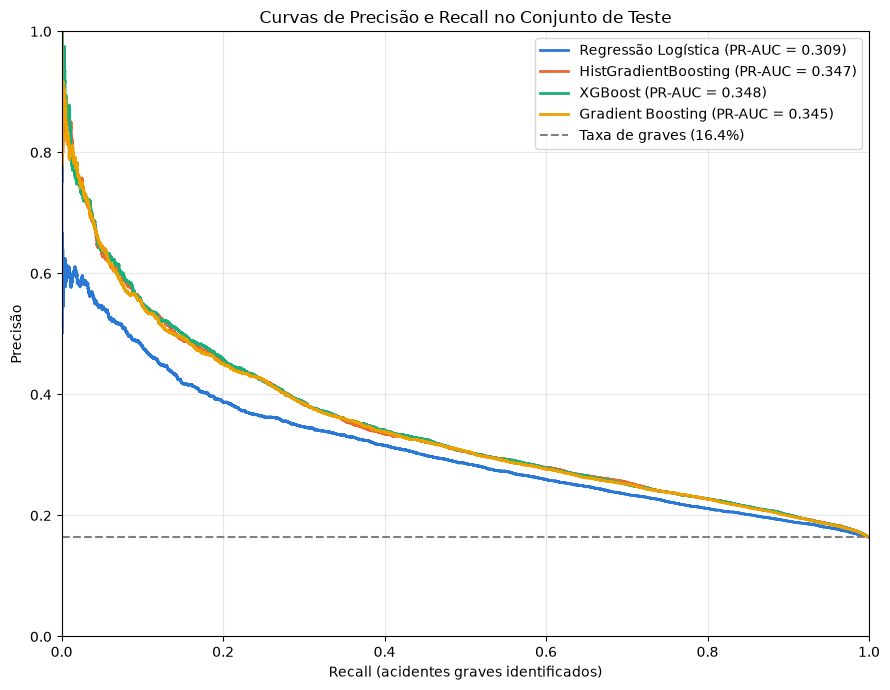

In [22]:
from src.modeling import evaluate_models_on_test
from src.visualization import plot_curvas_precisao_recall

metricas_teste_5, scores_teste_5 = evaluate_models_on_test(modelos_finais_5, limiares_5, X_teste, y_teste)
display(metricas_teste_5.round(4))
plot_curvas_precisao_recall(y_teste, {nome: scores for nome, scores in scores_teste_5.items() if nome != 'Dummy (baseline)'})

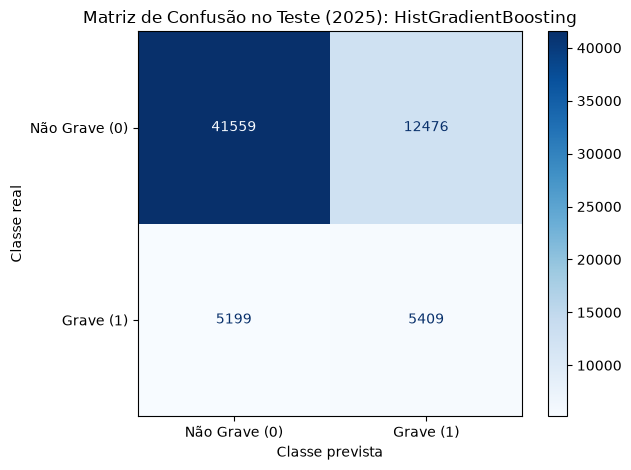

In [23]:
from src.visualization import plot_matriz_confusao

melhor_modelo_5 = resultados_5.index[0]
y_pred_melhor_5 = (scores_teste_5[melhor_modelo_5] >= limiares_5[melhor_modelo_5]).astype(int)
plot_matriz_confusao(y_teste, y_pred_melhor_5, titulo=f'Matriz de Confusão no Teste (2025): {melhor_modelo_5}')

In [24]:
from src.modeling import bootstrap_metric_ci, bootstrap_metric_difference

print("PR-AUC no teste com IC de 95% (bootstrap):")
display(pd.DataFrame({nome: bootstrap_metric_ci(y_teste, scores) for nome, scores in scores_teste_5.items()}).T.round(4))

comparacoes_5 = []
for nome, scores in scores_teste_5.items():
    if nome != melhor_modelo_5:
        diferenca = bootstrap_metric_difference(y_teste, scores_teste_5[melhor_modelo_5], scores)
        comparacoes_5.append({'comparacao': f'{melhor_modelo_5} - {nome}', **diferenca})

print(f"Diferença de PR-AUC no teste entre {melhor_modelo_5} e os demais modelos (bootstrap pareado):")
display(pd.DataFrame(comparacoes_5).set_index('comparacao').round(4))

PR-AUC no teste com IC de 95% (bootstrap):


,valor,ic_inferior,ic_superior
Dummy (baseline),0.1641,0.1613,0.1671
Regressão Logística,0.3094,0.3009,0.3179
HistGradientBoosting,0.3468,0.3379,0.3558
XGBoost,0.3484,0.3398,0.3573
Gradient Boosting,0.3455,0.3365,0.3547


Diferença de PR-AUC no teste entre HistGradientBoosting e os demais modelos (bootstrap pareado):


,diferenca,ic_inferior,ic_superior
comparacao,,,
HistGradientBoosting - Dummy (baseline),0.1827,0.1748,0.1907
HistGradientBoosting - Regressão Logística,0.0373,0.0316,0.0428
HistGradientBoosting - XGBoost,-0.0017,-0.0038,0.0006
HistGradientBoosting - Gradient Boosting,0.0013,-0.0012,0.0036


A PR-AUC e a ROC-AUC não dependem do limiar, enquanto a precisão, o recall, o F1 e a matriz de confusão utilizam o limiar escolhido no treino. Para verificar se as diferenças não se devem ao acaso da amostra de teste, o intervalo de confiança de 95% da PR-AUC é calculado por bootstrap (1.000 reamostragens com reposição), e as comparações entre dois modelos utilizam o bootstrap pareado, com as mesmas reamostragens para os dois.

No teste, os finalistas ficam na seguinte ordem: XGBoost, HistGradientBoosting e Gradient Boosting, seguidos pela Regressão Logística e pelo baseline. Os valores são menores que os da validação cruzada, mas a PR-AUC depende da proporção de graves (16,41% em 2025 contra 18,05% no treino), enquanto a ROC-AUC, que não depende dela, varia menos.

O bootstrap pareado mostra que o HistGradientBoosting é superior à Regressão Logística. Já os intervalos das diferenças para o Gradient Boosting e para o XGBoost incluem o zero, ou seja, a diferença do HistGradientBoosting para os outros dois modelos de gradient boosting não é significativa.

# Comparação entre os Recortes de 5 e 10 Anos

Esta seção verifica se o recorte de 10 anos melhora a predição em relação ao de 5 anos. Para isso, o baseline, os modelos lineares e os três finalistas são ajustados novamente com os dados de 2016 a 2024, com os mesmos espaços de busca. Em seguida, o baseline, a Regressão Logística e os finalistas são avaliados no mesmo teste (2025). Os demais modelos não lineares não são reajustados, por terem ficado atrás dos finalistas no recorte de 5 anos.

## 1. Treino de 10 anos (2016 a 2024)

In [25]:
resultados_lineares_10, modelos_lineares_10 = tune_models(get_linear_models(), X_treino_10, y_treino_10, cv)
display(resultados_lineares_10.round(4))

scale_pos_weight_10 = (y_treino_10 == 0).sum() / (y_treino_10 == 1).sum()
candidatos_nao_lineares_10 = get_nonlinear_models(scale_pos_weight_10)
finalistas_10 = {nome: candidatos_nao_lineares_10[nome] for nome in finalistas_nao_lineares}
resultados_nao_lineares_10, modelos_nao_lineares_10 = tune_models(finalistas_10, X_treino_10, y_treino_10, cv, n_iter=10)
display(resultados_nao_lineares_10.round(4))

[Dummy (baseline)] PR-AUC = 0.1802 ± 0.0000 (0.1 min)
[Regressão Logística] PR-AUC = 0.3244 ± 0.0027 (0.2 min)
[LDA] PR-AUC = 0.3242 ± 0.0021 (0.1 min)
[Ridge] PR-AUC = 0.3219 ± 0.0027 (0.2 min)
[LinearSVC] PR-AUC = 0.3240 ± 0.0027 (0.2 min)
[SGD] PR-AUC = 0.3243 ± 0.0026 (0.4 min)
[Perceptron] PR-AUC = 0.2289 ± 0.0254 (0.2 min)
[Nearest Centroid] PR-AUC = 0.2950 ± 0.0010 (0.1 min)
[Naive Bayes (Bernoulli)] PR-AUC = 0.2894 ± 0.0012 (0.1 min)
[Naive Bayes (Multinomial)] PR-AUC = 0.2719 ± 0.0019 (0.1 min)
[Naive Bayes (Complement)] PR-AUC = 0.2719 ± 0.0019 (0.1 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
Regressão Logística,0.3244,0.0027,0.6874,0.0021,{'model__C': 0.001},5,0.2
SGD,0.3243,0.0026,0.6873,0.0020,"{'model__alpha': 0.01, 'model__loss': 'log_loss'}",8,0.4
LDA,0.3242,0.0021,0.6864,0.0019,{},1,0.1
LinearSVC,0.3240,0.0027,0.6871,0.0021,{'model__C': 0.001},4,0.2
Ridge,0.3219,0.0027,0.6860,0.0020,{'model__alpha': 1000},5,0.2
Nearest Centroid,0.2950,0.0010,0.6627,0.0017,{'model__shrink_threshold': 1.0},4,0.1
Naive Bayes (Bernoulli),0.2894,0.0012,0.6664,0.0019,{'model__alpha': 0.01},3,0.1
Naive Bayes (Multinomial),0.2719,0.0019,0.6328,0.0030,{'model__alpha': 0.01},3,0.1
Naive Bayes (Complement),0.2719,0.0019,0.6328,0.0030,{'model__alpha': 0.01},3,0.1


[HistGradientBoosting] PR-AUC = 0.3692 ± 0.0015 (2.1 min)
[XGBoost] PR-AUC = 0.3686 ± 0.0013 (1.3 min)
[Gradient Boosting] PR-AUC = 0.3684 ± 0.0013 (13.6 min)


,pr_auc_media,pr_auc_desvio,roc_auc_media,roc_auc_desvio,melhores_parametros,combinacoes_testadas,tempo_min
modelo,,,,,,,
HistGradientBoosting,0.3692,0.0015,0.7147,0.0014,"{'model__min_samples_leaf': 100, 'model__max_leaf_nodes': 63, 'model__max_iter': 200, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}",10,2.1
XGBoost,0.3686,0.0013,0.7139,0.0015,"{'model__subsample': 0.8, 'model__n_estimators': 400, 'model__min_child_weight': 10, 'model__max_depth': 6, 'model__learning_rate': 0.1, 'model__colsample_bytree': 0.8}",10,1.3
Gradient Boosting,0.3684,0.0013,0.7145,0.0016,"{'model__subsample': 0.8, 'model__n_estimators': 400, 'model__min_samples_leaf': 1, 'model__max_depth': 5, 'model__learning_rate': 0.1}",10,13.6


In [26]:
modelos_finais_10 = {
    'Dummy (baseline)': modelos_lineares_10['Dummy (baseline)'],
    melhor_linear: modelos_lineares_10[melhor_linear],
    **modelos_nao_lineares_10
}

limiares_10 = {}
for nome, modelo in modelos_finais_10.items():
    limiar, f1_treino = find_best_threshold(modelo, X_treino_10, y_treino_10, cv)
    limiares_10[nome] = limiar
    print(f"[{nome}] limiar = {limiar:.4f} | F1 fora do fold = {f1_treino:.4f}")

metricas_teste_10, scores_teste_10 = evaluate_models_on_test(modelos_finais_10, limiares_10, X_teste, y_teste)
display(metricas_teste_10.round(4))

[Dummy (baseline)] limiar = 0.1802 | F1 fora do fold = 0.3053
[Regressão Logística] limiar = 0.5067 | F1 fora do fold = 0.3909
[HistGradientBoosting] limiar = 0.5400 | F1 fora do fold = 0.4106
[XGBoost] limiar = 0.5275 | F1 fora do fold = 0.4098
[Gradient Boosting] limiar = 0.2049 | F1 fora do fold = 0.4104


,pr_auc,roc_auc,limiar,precisao,recall,f1,verdadeiros_positivos,falsos_positivos,falsos_negativos,verdadeiros_negativos
modelo,,,,,,,,,,
Gradient Boosting,0.3521,0.7079,0.2049,0.3143,0.4893,0.3827,5190,11322,5418,42713
HistGradientBoosting,0.3517,0.7081,0.5400,0.3093,0.4994,0.3820,5298,11829,5310,42206
XGBoost,0.3513,0.7072,0.5275,0.3042,0.5089,0.3808,5398,12348,5210,41687
Regressão Logística,0.3099,0.6805,0.5067,0.2774,0.5288,0.3639,5610,14617,4998,39418
Dummy (baseline),0.1641,0.5000,0.1802,0.1641,1.0000,0.2819,10608,54035,0,0


No recorte de 10 anos, a Regressão Logística continua sendo o melhor modelo linear (0,3244), e o HistGradientBoosting mantém a maior PR-AUC média entre os finalistas (0,3692), seguido de perto pelo XGBoost e pelo Gradient Boosting. Esses valores não devem ser comparados diretamente com os do recorte de 5 anos, pois as partições de validação contêm anos diferentes. Por isso, a comparação entre os recortes é feita no teste.

No teste, os três modelos de gradient boosting do recorte de 10 anos ficaram um pouco à frente das versões de 5 anos (no XGBoost, por exemplo, 0,3513 contra 0,3484), enquanto a Regressão Logística ficou praticamente igual (0,3099 contra 0,3094).

## 2. Comparação no mesmo conjunto de teste

,modelo,recorte,valor,ic_inferior,ic_superior
0,Regressão Logística,5 anos (2021-2024),0.3094,0.3009,0.3179
1,Regressão Logística,10 anos (2016-2024),0.3099,0.3014,0.3185
2,HistGradientBoosting,5 anos (2021-2024),0.3468,0.3379,0.3558
3,HistGradientBoosting,10 anos (2016-2024),0.3517,0.3428,0.3605
4,XGBoost,5 anos (2021-2024),0.3484,0.3398,0.3573
5,XGBoost,10 anos (2016-2024),0.3513,0.3424,0.3600
6,Gradient Boosting,5 anos (2021-2024),0.3455,0.3365,0.3547
7,Gradient Boosting,10 anos (2016-2024),0.3521,0.3433,0.3612


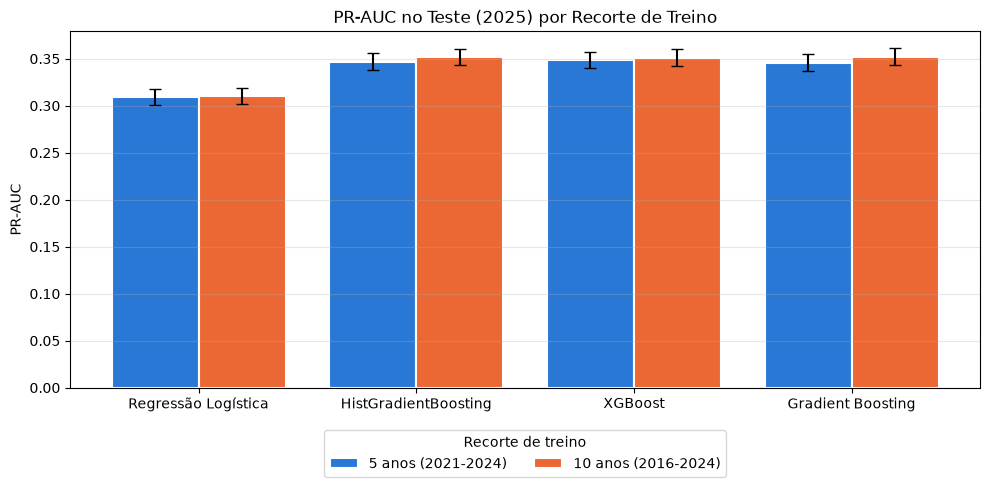

In [27]:
from src.visualization import plot_comparacao_recortes

modelos_comparados = [nome for nome in modelos_finais_5 if nome != 'Dummy (baseline)']

linhas = []
for nome in modelos_comparados:
    linhas.append({'modelo': nome, 'recorte': '5 anos (2021-2024)', **bootstrap_metric_ci(y_teste, scores_teste_5[nome])})
    linhas.append({'modelo': nome, 'recorte': '10 anos (2016-2024)', **bootstrap_metric_ci(y_teste, scores_teste_10[nome])})
comparacao_recortes = pd.DataFrame(linhas)
display(comparacao_recortes.round(4))
plot_comparacao_recortes(comparacao_recortes)

In [28]:
diferencas_recortes = []
for nome in modelos_comparados:
    diferenca = bootstrap_metric_difference(y_teste, scores_teste_10[nome], scores_teste_5[nome])
    diferencas_recortes.append({'modelo': nome, **diferenca})

print("Diferença de PR-AUC no teste (10 anos - 5 anos), com IC de 95% (bootstrap pareado):")
display(pd.DataFrame(diferencas_recortes).set_index('modelo').round(4))

Diferença de PR-AUC no teste (10 anos - 5 anos), com IC de 95% (bootstrap pareado):


,diferenca,ic_inferior,ic_superior
modelo,,,
Regressão Logística,0.0005,0.0001,0.0008
HistGradientBoosting,0.0049,0.0028,0.0070
XGBoost,0.0029,0.0002,0.0055
Gradient Boosting,0.0066,0.0037,0.0093


Para cada modelo, a diferença de PR-AUC entre os dois recortes foi calculada por bootstrap pareado, nas mesmas 1.000 reamostragens do teste. O ganho do recorte de 10 anos é estatisticamente significativo nos três modelos de gradient boosting, já que nenhum dos intervalos de confiança inclui o zero, mas é pequeno: 0,0049 no HistGradientBoosting, 0,0029 no XGBoost e 0,0066 no Gradient Boosting. Na Regressão Logística, a diferença (0,0005) é estatisticamente significativa (IC de 0,0001 a 0,0008), mas desprezível na prática. Portanto, a escolha do algoritmo, que separa a Regressão Logística dos modelos de gradient boosting em cerca de 0,04, teve impacto muito maior que a ampliação do histórico.

# Considerações Finais

Os principais resultados desta etapa foram:
1. Seleção de atributos: Apenas os três atributos redundantes foram removidos. A análise das combinações mostrou que o ranking individual precisa ser analisado com mais cautela, já que `has_motocicleta_envolvida`, um dos atributos de menor F-score, está entre os que mais contribuem para o desempenho.
2. Comparação entre modelos: Os três modelos de gradient boosting foram os melhores entre todos os avaliados. No teste, com o recorte de 5 anos, o HistGradientBoosting obteve PR-AUC de 0,3468, contra 0,3094 da Regressão Logística e 0,1641 do baseline, sem diferença significativa para o XGBoost e o Gradient Boosting.
3. Recortes temporais: O recorte de 10 anos trouxe um ganho pequeno, mas significativo, para os modelos de gradient boosting, e nenhum ganho significativo para a Regressão Logística.

Limitações:
- Parte dos atributos, como a quantidade e a idade das vítimas e as condições da via, vem do boletim de ocorrência e pode não estar disponível no momento do chamado.
- A proporção de graves em 2025 (16,41%) é menor que a dos anos de treino, o que dificulta a comparação direta entre as métricas do teste e as da validação cruzada.
- Os espaços de busca de hiperparâmetros foram limitados: nos modelos com mais de 10 combinações, foram testadas apenas 10 e, em vários modelos, inclusive na Regressão Logística, o melhor valor ficou no limite da grade testada.
- No recorte de 10 anos, apenas os finalistas não lineares foram reajustados.